In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, auc, confusion_matrix, f1_score, log_loss,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [2]:
repo_root = Path.cwd()
if repo_root.name in {'vanilla-code', 'your-sollution', 'your_solution'}:
    repo_root = repo_root.parent

def dataset_path(task_name: str, filename: str) -> str:
    local_path = repo_root / 'dataset' / task_name / filename
    if local_path.exists():
        return str(local_path)
    return (
        'https://github.com/AI-is-out-there/'
        'check-your-biomed-datascience-skills-review/raw/refs/heads/dev/'
        f'dataset/{task_name}/{filename}'
    )

df = pd.read_csv(dataset_path('task1', 'train.csv'))
test_features = pd.read_csv(dataset_path('task1', 'test_features.csv'))

TARGETS = ['prediction', 'Статус_глюкозы', 'Доклинический_риск']
FEATURES = [c for c in df.columns if c not in TARGETS + ['patient_id']]

print('train:', df.shape, '| test:', test_features.shape)
print('признаков:', len(FEATURES))
print('столбцы test, не являющиеся признаками:', [c for c in test_features.columns if c not in FEATURES])
df.head()

train: (800, 19) | test: (200, 18)
признаков: 15
столбцы test, не являющиеся признаками: ['patient_id', 'Статус_глюкозы', 'Доклинический_риск']


,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,prediction,Статус_глюкозы,Доклинический_риск
0,1,41,1,24.240,81.040,113.190,62.540,50.650,4.595,4.650,NaN,NaN,1.379,115.520,0,165.800,0,0,0
1,4,53,0,19.840,73.440,119.750,71.590,48.150,4.431,5.080,2.268,2.022,1.467,93.390,0,248.100,0,0,0
2,5,53,1,24.280,82.060,127.070,70.340,56.730,4.997,5.040,2.459,1.325,0.967,88.410,0,230.500,0,0,0
3,6,60,1,25.190,91.890,116.980,82.000,34.980,5.491,5.000,3.700,0.722,1.505,91.060,1,132.500,1,0,0
4,7,59,1,24.450,84.070,129.120,82.700,46.420,6.456,4.800,3.960,1.406,2.274,89.740,1,177.400,1,2,0


In [3]:
missing = pd.DataFrame({
    'пропуски train': df[FEATURES].isna().sum(),
    'доля train': df[FEATURES].isna().mean(),
    'пропуски test': test_features[FEATURES].isna().sum(),
})
display(missing[missing['пропуски train'] > 0])
display(df[FEATURES].describe().T)

,пропуски train,доля train,пропуски test
ЛПНП_ммоль_л,35,0.044,10
ЛПВП_ммоль_л,45,0.056,11
Триглицериды_ммоль_л,46,0.058,15
СКФ_мл_мин,47,0.059,14


,count,mean,std,min,25%,50%,75%,max
Возраст,800.000,52.256,7.563,40.000,45.000,53.000,59.000,65.000
Пол_мужской,800.000,0.446,0.497,0.000,0.000,0.000,1.000,1.000
ИМТ,800.000,23.568,3.229,16.000,21.120,23.595,26.035,33.890
Окружность_талии_см,800.000,86.178,6.026,68.860,81.968,86.160,90.505,104.630
САД_мм_рт_ст,800.000,114.084,11.162,90.000,106.627,114.475,121.957,147.970
ДАД_мм_рт_ст,800.000,70.346,7.099,50.000,65.450,70.435,75.028,90.620
Пульсовое_давление,800.000,43.738,10.345,9.060,36.847,43.895,50.398,73.950
Глюкоза_натощак_ммоль_л,800.000,5.070,0.769,3.500,4.534,5.006,5.603,7.348
HbA1c_%,800.000,5.019,0.365,4.000,4.780,5.010,5.280,6.020
ЛПНП_ммоль_л,765.000,2.983,0.643,1.207,2.556,2.987,3.415,5.115


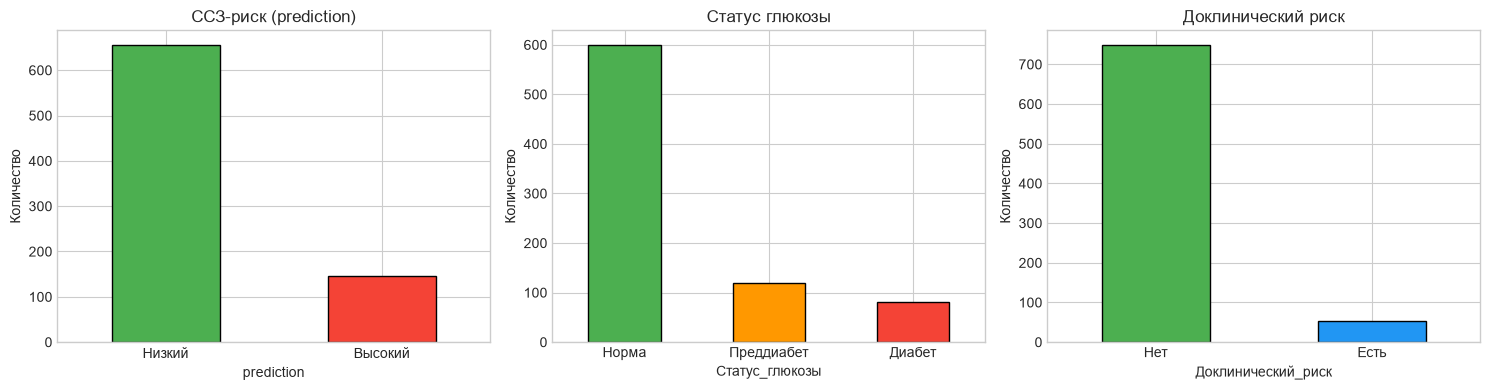

Доля высокого ССЗ-риска: 0.181


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['prediction'].map({0: 'Низкий', 1: 'Высокий'}).value_counts().plot(kind='bar', ax=axes[0], color=['#4CAF50', '#F44336'], edgecolor='black')
axes[0].set_title('ССЗ-риск (prediction)')
df['Статус_глюкозы'].map({0: 'Норма', 1: 'Преддиабет', 2: 'Диабет'}).value_counts().plot(kind='bar', ax=axes[1], color=['#4CAF50', '#FF9800', '#F44336'], edgecolor='black')
axes[1].set_title('Статус глюкозы')
df['Доклинический_риск'].map({0: 'Нет', 1: 'Есть'}).value_counts().plot(kind='bar', ax=axes[2], color=['#4CAF50', '#2196F3'], edgecolor='black')
axes[2].set_title('Доклинический риск')
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
    ax.set_ylabel('Количество')
plt.tight_layout()
plt.show()

print('Доля высокого ССЗ-риска:', round(df['prediction'].mean(), 3))

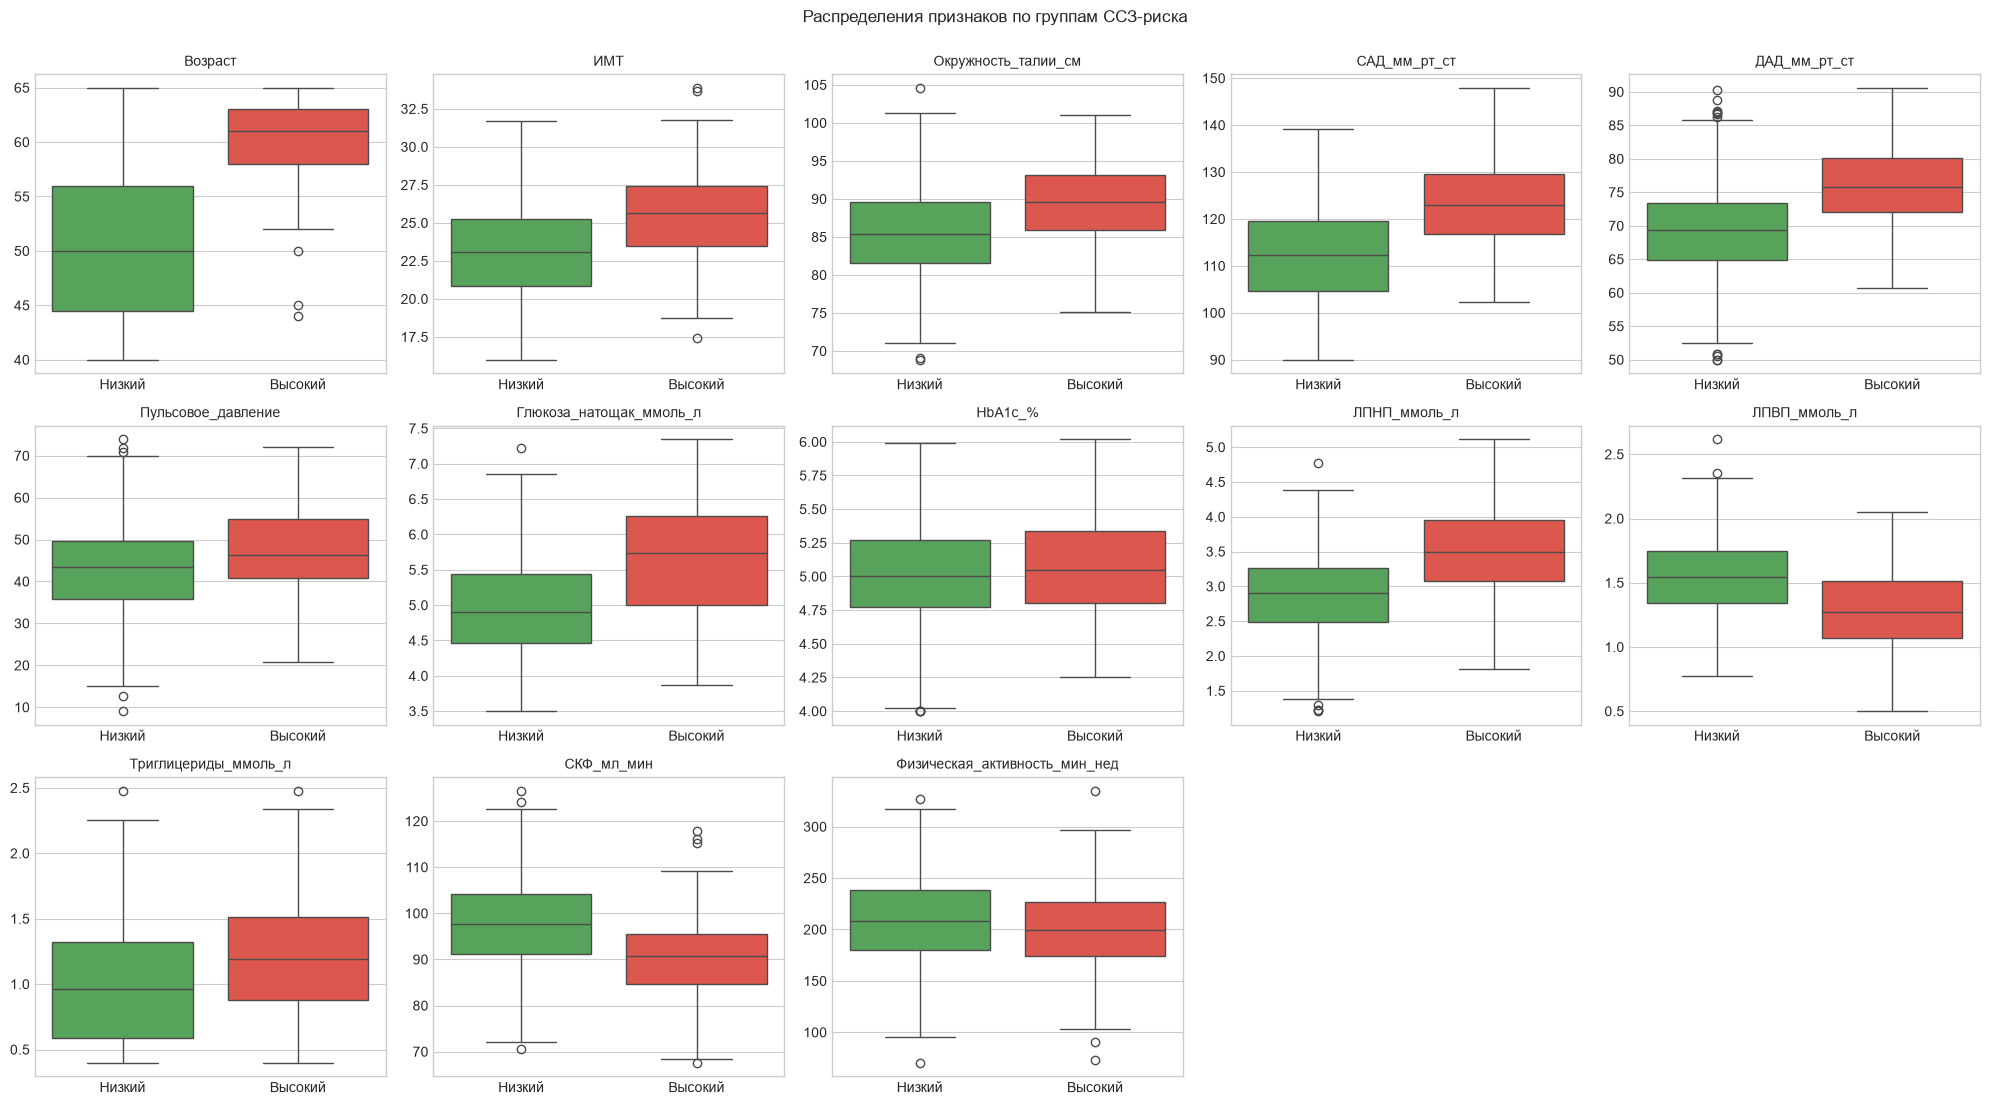

,Пол_мужской,Курение
prediction,,
Низкий,0.395,0.198
Высокий,0.676,0.641


In [5]:
num_features = [c for c in FEATURES if df[c].nunique() > 2]
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, col in zip(axes.ravel(), num_features):
    sns.boxplot(data=df, x='prediction', y=col, hue='prediction', ax=ax, palette=['#4CAF50', '#F44336'], legend=False)
    ax.set_xticks([0, 1], ['Низкий', 'Высокий'])
    ax.set_xlabel('')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('')
for ax in axes.ravel()[len(num_features):]:
    ax.axis('off')
plt.suptitle('Распределения признаков по группам ССЗ-риска', y=1.0)
plt.tight_layout()
plt.show()

display(df.groupby('prediction')[['Пол_мужской', 'Курение']].mean().rename(index={0: 'Низкий', 1: 'Высокий'}))

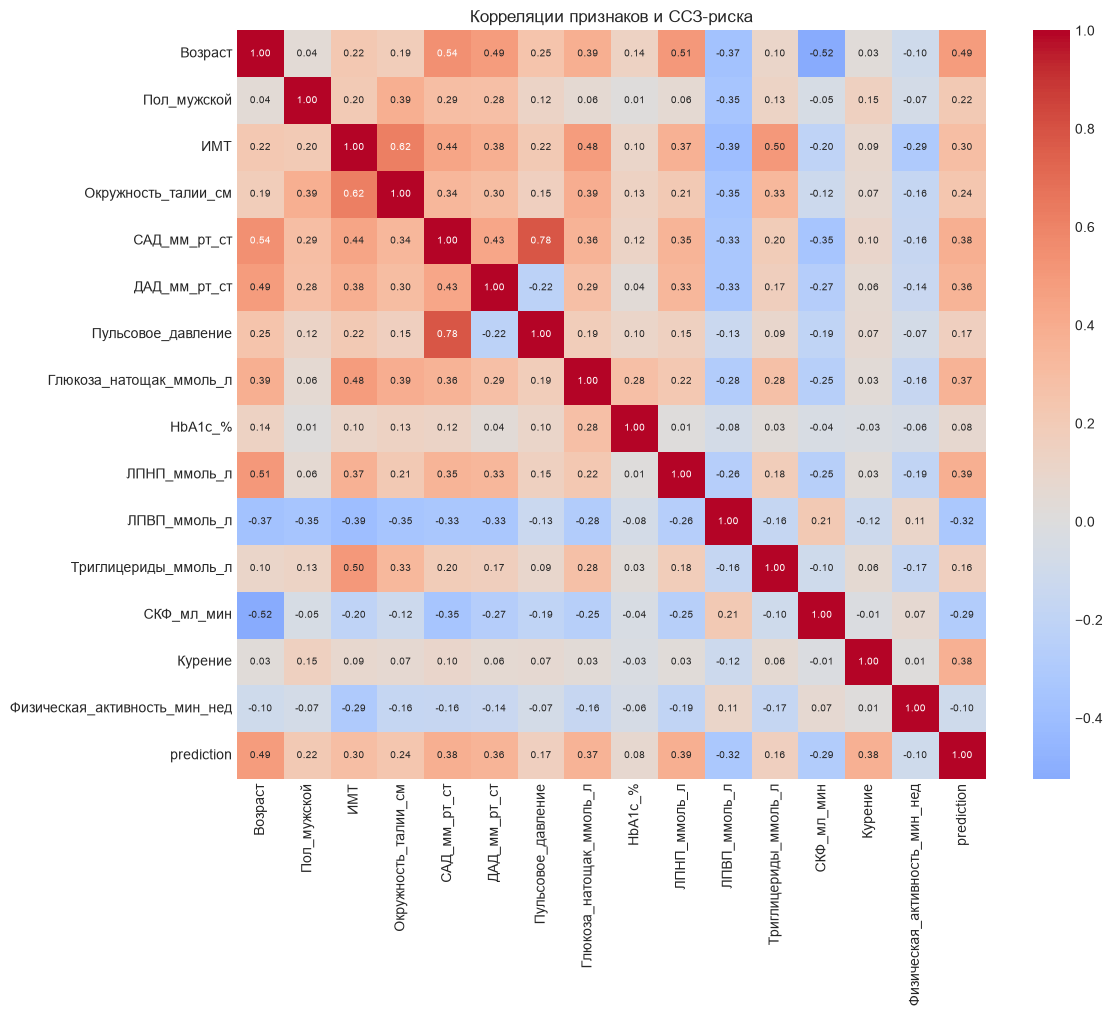

Корреляция с prediction:
Возраст                          0.494
ЛПНП_ммоль_л                     0.386
САД_мм_рт_ст                     0.381
Курение                          0.381
Глюкоза_натощак_ммоль_л          0.366
ДАД_мм_рт_ст                     0.357
ЛПВП_ммоль_л                    -0.320
ИМТ                              0.296
СКФ_мл_мин                      -0.285
Окружность_талии_см              0.237
Пол_мужской                      0.217
Пульсовое_давление               0.166
Триглицериды_ммоль_л             0.164
Физическая_активность_мин_нед   -0.103
HbA1c_%                          0.075


In [6]:
corr = df[FEATURES + ['prediction']].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, square=True)
plt.title('Корреляции признаков и ССЗ-риска')
plt.tight_layout()
plt.show()

print('Корреляция с prediction:')
print(corr['prediction'].drop('prediction').sort_values(key=abs, ascending=False).round(3).to_string())

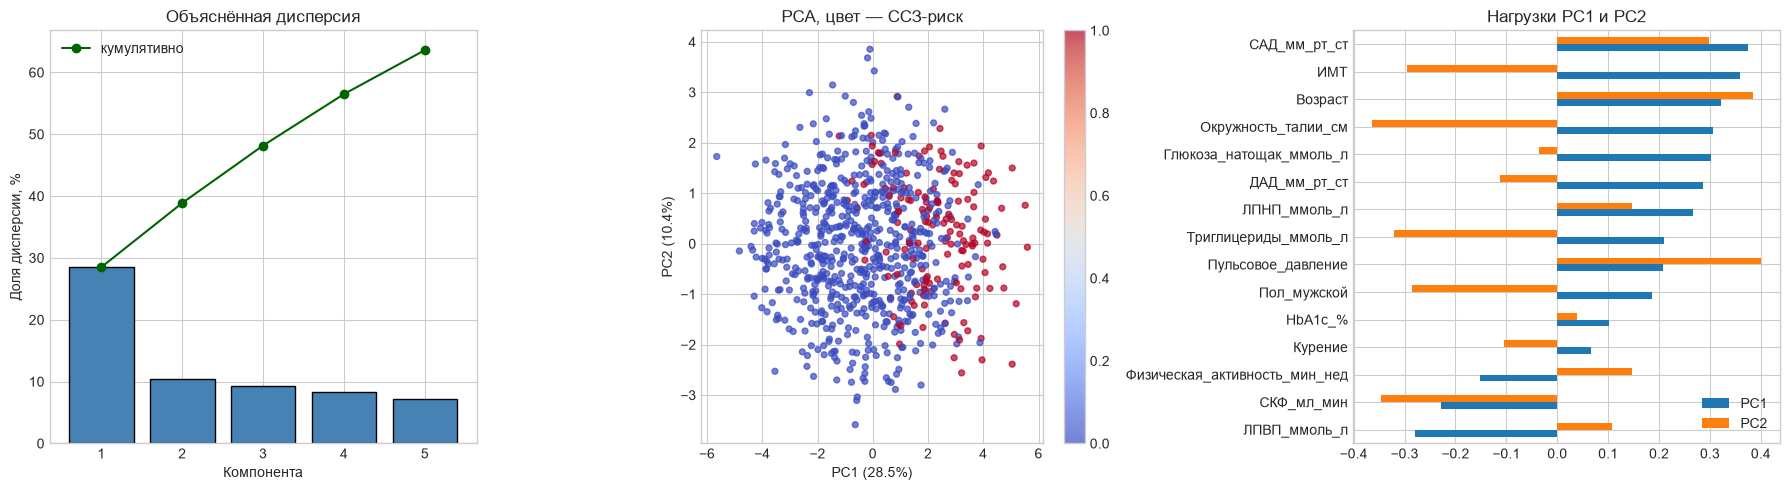

In [7]:
X_eda = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(df[FEATURES]))
pca = PCA(n_components=5, random_state=SEED).fit(X_eda)
pcs = pca.transform(X_eda)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(range(1, 6), pca.explained_variance_ratio_ * 100, color='steelblue', edgecolor='black')
axes[0].plot(range(1, 6), np.cumsum(pca.explained_variance_ratio_) * 100, marker='o', color='darkgreen', label='кумулятивно')
axes[0].set_xlabel('Компонента')
axes[0].set_ylabel('Доля дисперсии, %')
axes[0].set_title('Объяснённая дисперсия')
axes[0].legend()

sc = axes[1].scatter(pcs[:, 0], pcs[:, 1], c=df['prediction'], cmap='coolwarm', s=18, alpha=0.7)
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[1].set_title('PCA, цвет — ССЗ-риск')
plt.colorbar(sc, ax=axes[1])

loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=['PC1', 'PC2'])
loadings.sort_values('PC1').plot(kind='barh', ax=axes[2])
axes[2].set_title('Нагрузки PC1 и PC2')
plt.tight_layout()
plt.show()

In [8]:
X = df[FEATURES]
y = df['prediction'].to_numpy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print('train:', X_train.shape, f'(высокий риск {y_train.mean():.1%})')
print('valid:', X_valid.shape, f'(высокий риск {y_valid.mean():.1%})')

pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)),
])
param_grid = {
    'svc__kernel': ['rbf', 'linear'],
    'svc__C': [0.1, 0.3, 1, 3, 10],
    'svc__gamma': ['scale', 0.01, 0.03, 0.1],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(pipe, param_grid, scoring='roc_auc', cv=cv, n_jobs=-1)
search.fit(X_train, y_train)

print('Лучшие параметры:', search.best_params_)
print(f'ROC-AUC на кросс-валидации: {search.best_score_:.3f} ± {search.cv_results_["std_test_score"][search.best_index_]:.3f}')
cv_table = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
display(cv_table[['param_svc__kernel', 'param_svc__C', 'param_svc__gamma', 'mean_test_score', 'std_test_score']].head(8))

train: (640, 15) (высокий риск 18.1%)
valid: (160, 15) (высокий риск 18.1%)


Лучшие параметры: {'svc__C': 10, 'svc__gamma': 0.03, 'svc__kernel': 'rbf'}
ROC-AUC на кросс-валидации: 0.981 ± 0.011


,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_score,std_test_score
36,rbf,10.000,0.030,0.981,0.011
28,rbf,3.000,0.030,0.979,0.013
34,rbf,10.000,0.010,0.978,0.011
32,rbf,10.000,scale,0.976,0.013
24,rbf,3.000,scale,0.976,0.012
16,rbf,1.000,scale,0.975,0.015
20,rbf,1.000,0.030,0.973,0.015
22,rbf,1.000,0.100,0.972,0.015


,"SVM, валидация"
Accuracy,0.969
Recall,0.931
Specificity,0.977
Precision,0.900
F1,0.915
ROC-AUC,0.992


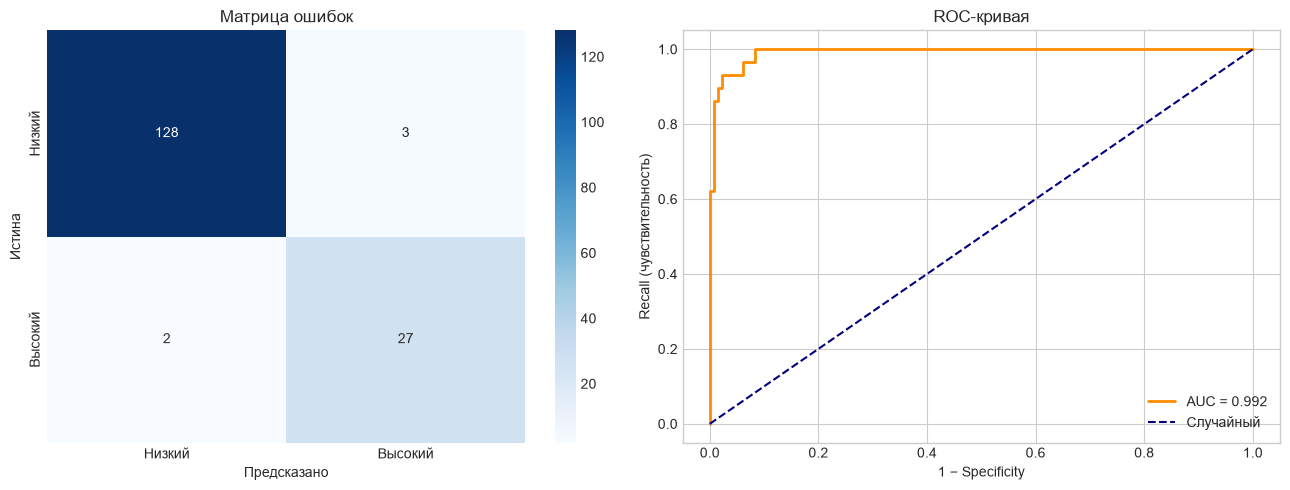

In [9]:
model = search.best_estimator_
proba_valid = model.predict_proba(X_valid)[:, 1]
pred_valid = model.predict(X_valid)

def metrics(y_true, y_pred, y_score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'Specificity': tn / (tn + fp),
        'Precision': precision_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_score),
    }

valid_metrics = metrics(y_valid, pred_valid, proba_valid)
display(pd.Series(valid_metrics, name='SVM, валидация').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_valid, pred_valid)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Низкий', 'Высокий'], yticklabels=['Низкий', 'Высокий'])
axes[0].set_xlabel('Предсказано')
axes[0].set_ylabel('Истина')
axes[0].set_title('Матрица ошибок')

fpr, tpr, _ = roc_curve(y_valid, proba_valid)
axes[1].plot(fpr, tpr, lw=2, color='darkorange', label=f'AUC = {auc(fpr, tpr):.3f}')
axes[1].plot([0, 1], [0, 1], '--', color='navy', label='Случайный')
axes[1].set_xlabel('1 − Specificity')
axes[1].set_ylabel('Recall (чувствительность)')
axes[1].set_title('ROC-кривая')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

In [10]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]
rows = []
for t in thresholds:
    p = (proba_valid >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, p).ravel()
    rows.append({'порог': t, 'Recall': tp / (tp + fn), 'Specificity': tn / (tn + fp),
                 'Precision': precision_score(y_valid, p, zero_division=0), 'F1': f1_score(y_valid, p),
                 'ложноотрицательные': fn, 'ложноположительные': fp})
display(pd.DataFrame(rows).set_index('порог'))

,Recall,Specificity,Precision,F1,ложноотрицательные,ложноположительные
порог,,,,,,
0.200,1.000,0.908,0.707,0.829,0,12
0.300,0.966,0.931,0.757,0.848,1,9
0.400,0.931,0.977,0.900,0.915,2,3
0.500,0.759,0.992,0.957,0.846,7,1
0.600,0.690,0.992,0.952,0.800,9,1


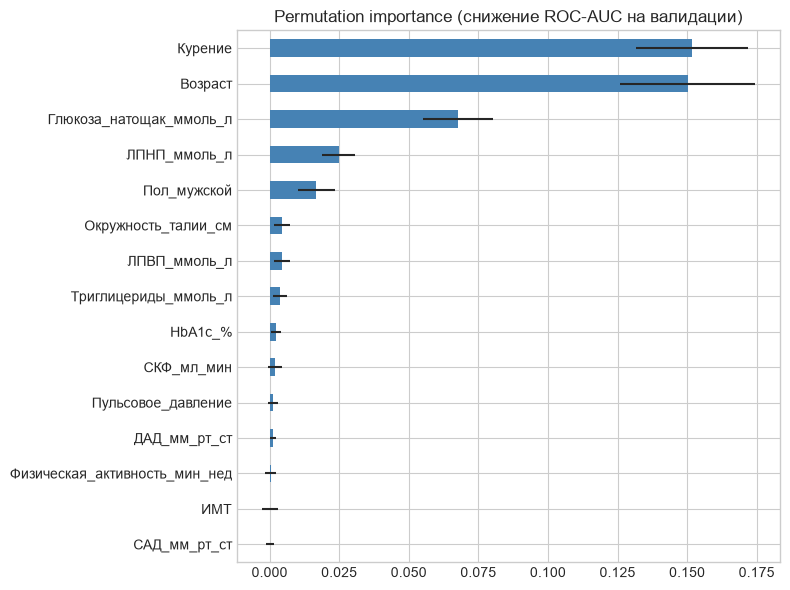

Курение                   0.152
Возраст                   0.150
Глюкоза_натощак_ммоль_л   0.068
ЛПНП_ммоль_л              0.025
Пол_мужской               0.017
Окружность_талии_см       0.004


In [11]:
imp = permutation_importance(model, X_valid, y_valid, scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(8, 6))
importance.plot(kind='barh', xerr=pd.Series(imp.importances_std, index=FEATURES)[importance.index], color='steelblue')
plt.title('Permutation importance (снижение ROC-AUC на валидации)')
plt.tight_layout()
plt.show()
print(importance.sort_values(ascending=False).head(6).round(3).to_string())

In [12]:
GLU = 'Глюкоза_натощак_ммоль_л'
border = df[(df[GLU] >= 5.4) & (df[GLU] <= 6.5)].copy()
status_names = ['Норма', 'Преддиабет', 'Диабет']
print('Пограничная группа в train:', len(border))
print(border['Статус_глюкозы'].map(dict(enumerate(status_names))).value_counts().to_string())

FUZZY_FEATURES = [GLU, 'HbA1c_%', 'ИМТ', 'Окружность_талии_см', 'Триглицериды_ммоль_л', 'ЛПВП_ммоль_л', 'Возраст']
Xb = border[FUZZY_FEATURES]
yb = border['Статус_глюкозы'].to_numpy()
Xb_train, Xb_valid, yb_train, yb_valid = train_test_split(Xb, yb, test_size=0.3, random_state=SEED, stratify=yb)

fuzzy_prep = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
Zb_train = fuzzy_prep.fit_transform(Xb_train)
Zb_valid = fuzzy_prep.transform(Xb_valid)

Пограничная группа в train: 247
Статус_глюкозы
Преддиабет    120
Норма          69
Диабет         58


In [13]:
class FuzzyKNN:
    def __init__(self, k=7, m=2.0, n_classes=3):
        self.k, self.m, self.n_classes = k, m, n_classes

    def fit(self, X, y):
        self.X_ = np.asarray(X)
        self.y_ = np.asarray(y).astype(int)
        self.train_memberships_ = self._init_memberships()
        return self

    def _init_memberships(self):
        d = np.linalg.norm(self.X_[:, None, :] - self.X_[None, :, :], axis=2)
        np.fill_diagonal(d, np.inf)
        idx = np.argsort(d, axis=1)[:, :self.k]
        u = np.zeros((len(self.y_), self.n_classes))
        for i in range(len(self.y_)):
            share = np.bincount(self.y_[idx[i]], minlength=self.n_classes) / self.k
            u[i] = 0.49 * share
            u[i, self.y_[i]] += 0.51
        return u

    def predict_membership(self, X):
        X = np.asarray(X)
        d = np.linalg.norm(X[:, None, :] - self.X_[None, :, :], axis=2)
        idx = np.argsort(d, axis=1)[:, :self.k]
        dk = np.maximum(np.take_along_axis(d, idx, axis=1), 1e-10)
        w = 1.0 / dk ** (2 / (self.m - 1))
        u = np.einsum('ij,ijc->ic', w, self.train_memberships_[idx]) / w.sum(axis=1, keepdims=True)
        return u / u.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.predict_membership(X).argmax(axis=1)

def risk_score(u):
    return 0.5 * u[:, 1] + 1.0 * u[:, 2]

def uncertainty(u):
    return 1 - u.max(axis=1)

rows = []
for k in [3, 5, 7, 9, 11, 15]:
    u = FuzzyKNN(k=k).fit(Zb_train, yb_train).predict_membership(Zb_valid)
    u_clip = np.clip(u, 1e-6, 1)
    u_clip /= u_clip.sum(axis=1, keepdims=True)
    rows.append({'k': k, 'accuracy': accuracy_score(yb_valid, u.argmax(1)),
                 'macro F1': f1_score(yb_valid, u.argmax(1), average='macro'),
                 'log-loss': log_loss(yb_valid, u_clip, labels=[0, 1, 2])})
k_table = pd.DataFrame(rows).set_index('k')
display(k_table)
best_k = int(k_table['log-loss'].idxmin())
print('Выбрано k =', best_k, '(минимальный log-loss на валидации)')

,accuracy,macro F1,log-loss
k,,,
3,0.707,0.699,0.898
5,0.680,0.665,0.574
7,0.760,0.756,0.552
9,0.720,0.705,0.557
11,0.773,0.766,0.568
15,0.773,0.760,0.605


Выбрано k = 7 (минимальный log-loss на валидации)


Нечёткий KNN (argmax): accuracy=0.760, macro F1=0.756
Неопределённых случаев (max принадлежность < 0.6): 21 из 75
Accuracy на уверенных: 0.815, на неопределённых: 0.619
Обычный KNN (k=7): accuracy=0.787, macro F1=0.786


,прогноз: Норма,прогноз: Преддиабет,прогноз: Диабет
истина: Норма,12,9,0
истина: Преддиабет,4,32,0
истина: Диабет,0,5,13


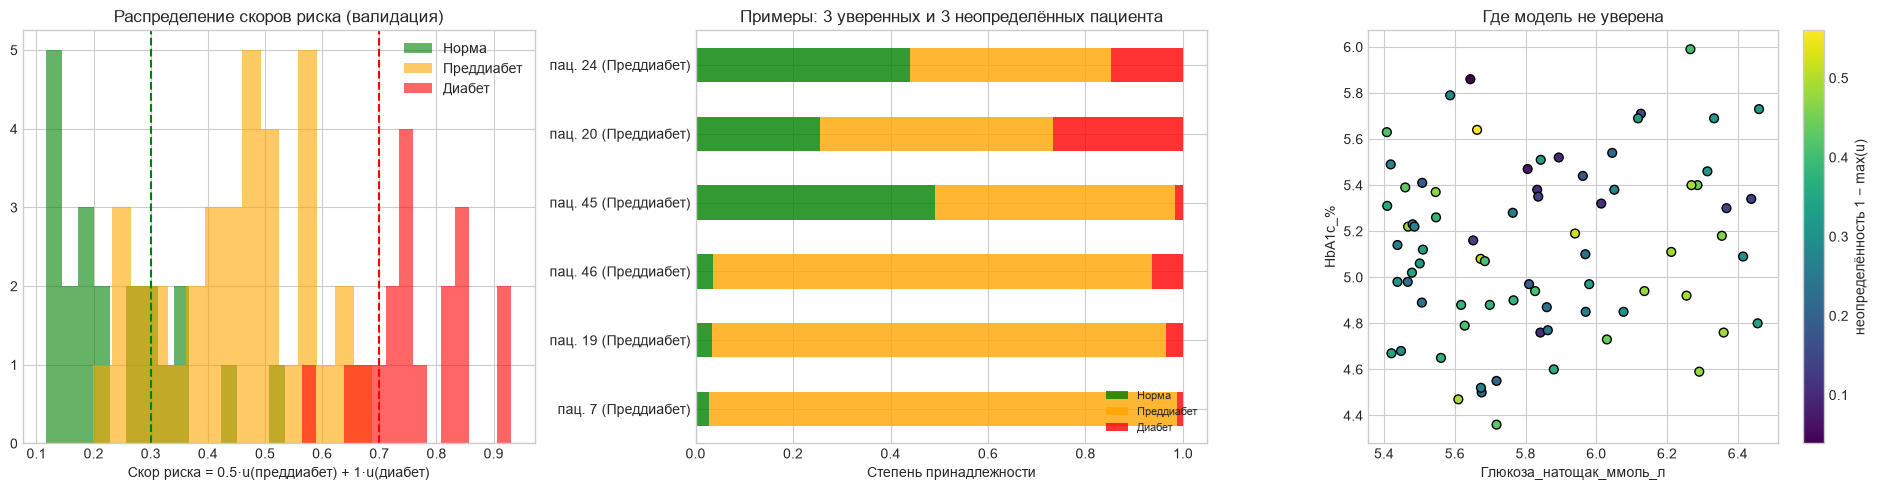

In [14]:
fknn = FuzzyKNN(k=best_k).fit(Zb_train, yb_train)
u_valid = fknn.predict_membership(Zb_valid)
r_valid = risk_score(u_valid)
unc_valid = uncertainty(u_valid)
uncertain = unc_valid > 0.4

hard_pred = u_valid.argmax(1)
print(f'Нечёткий KNN (argmax): accuracy={accuracy_score(yb_valid, hard_pred):.3f}, macro F1={f1_score(yb_valid, hard_pred, average="macro"):.3f}')
print(f'Неопределённых случаев (max принадлежность < 0.6): {uncertain.sum()} из {len(uncertain)}')
print(f'Accuracy на уверенных: {accuracy_score(yb_valid[~uncertain], hard_pred[~uncertain]):.3f}, '
      f'на неопределённых: {accuracy_score(yb_valid[uncertain], hard_pred[uncertain]):.3f}')

crisp = KNeighborsClassifier(n_neighbors=best_k).fit(Zb_train, yb_train).predict(Zb_valid)
print(f'Обычный KNN (k={best_k}): accuracy={accuracy_score(yb_valid, crisp):.3f}, macro F1={f1_score(yb_valid, crisp, average="macro"):.3f}')
display(pd.DataFrame(confusion_matrix(yb_valid, hard_pred), index=[f'истина: {s}' for s in status_names],
                     columns=[f'прогноз: {s}' for s in status_names]))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for c, color in zip(range(3), ['green', 'orange', 'red']):
    axes[0].hist(r_valid[yb_valid == c], bins=15, alpha=0.6, color=color, label=status_names[c])
axes[0].axvline(0.3, ls='--', color='green')
axes[0].axvline(0.7, ls='--', color='red')
axes[0].set_xlabel('Скор риска = 0.5·u(преддиабет) + 1·u(диабет)')
axes[0].set_title('Распределение скоров риска (валидация)')
axes[0].legend()

examples = np.r_[np.argsort(unc_valid)[:3], np.argsort(unc_valid)[-3:]]
pd.DataFrame(u_valid[examples], columns=status_names,
             index=[f'пац. {i} ({status_names[yb_valid[i]]})' for i in examples]).plot(
    kind='barh', stacked=True, ax=axes[1], color=['green', 'orange', 'red'], alpha=0.8)
axes[1].set_xlabel('Степень принадлежности')
axes[1].set_title('Примеры: 3 уверенных и 3 неопределённых пациента')
axes[1].legend(loc='lower right', fontsize=8)

sc = axes[2].scatter(Xb_valid[GLU], Xb_valid['HbA1c_%'], c=unc_valid, cmap='viridis', s=40, edgecolors='k')
plt.colorbar(sc, ax=axes[2], label='неопределённость 1 − max(u)')
axes[2].set_xlabel(GLU)
axes[2].set_ylabel('HbA1c_%')
axes[2].set_title('Где модель не уверена')
plt.tight_layout()
plt.show()

In [15]:
test_border = test_features[(test_features[GLU] >= 5.4) & (test_features[GLU] <= 6.5)]
fknn_full_prep = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
Zb_full = fknn_full_prep.fit_transform(Xb)
fknn_full = FuzzyKNN(k=best_k).fit(Zb_full, yb)
u_test = fknn_full.predict_membership(fknn_full_prep.transform(test_border[FUZZY_FEATURES]))

test_fuzzy = pd.DataFrame(u_test, columns=[f'u_{s}' for s in status_names], index=test_border['patient_id'])
test_fuzzy['скор_риска'] = risk_score(u_test)
test_fuzzy['неопределённость'] = uncertainty(u_test)
test_fuzzy['неопределённый'] = test_fuzzy['неопределённость'] > 0.4
print(f'Пограничных пациентов в test: {len(test_fuzzy)}, из них неопределённых: {test_fuzzy["неопределённый"].sum()}')
display(test_fuzzy.sort_values('неопределённость', ascending=False).head(10))

Пограничных пациентов в test: 66, из них неопределённых: 18


,u_Норма,u_Преддиабет,u_Диабет,скор_риска,неопределённость,неопределённый
patient_id,,,,,,
591,0.495,0.499,0.006,0.255,0.501,True
860,0.028,0.472,0.500,0.736,0.500,True
749,0.504,0.496,0.000,0.248,0.496,True
460,0.513,0.472,0.015,0.251,0.487,True
529,0.467,0.514,0.019,0.276,0.486,True
827,0.027,0.521,0.452,0.712,0.479,True
412,0.451,0.530,0.019,0.284,0.470,True
509,0.469,0.531,0.000,0.265,0.469,True
886,0.444,0.548,0.009,0.283,0.452,True


In [16]:
final_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('svc', SVC(class_weight='balanced', probability=True, random_state=SEED)),
]).set_params(**search.best_params_)
final_model.fit(X, y)

test_pred = final_model.predict(test_features[FEATURES])
submission = pd.DataFrame({'patient_id': test_features['patient_id'], 'prediction': test_pred.astype(int)})

assert len(submission) == len(test_features)
assert submission['patient_id'].equals(test_features['patient_id'])
assert submission['prediction'].notna().all() and set(submission['prediction']) <= {0, 1}

output_path = repo_root / 'outputs' / 'task1_predictions.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(output_path, index=False)
print('Сохранено:', output_path.relative_to(repo_root).as_posix())
print('Доля высокого риска в прогнозе:', round(submission['prediction'].mean(), 3))

Сохранено: outputs/task1_predictions.csv
Доля высокого риска в прогнозе: 0.2


Отчёт

Для прогноза взяты 15 клинических показателей. Статус глюкозы и доклинический риск не входят, т.к. являются по факту ответами. Пропуски в липидах и СКФ заполнены медианой, данные стандартизованы.

Пациентов с высоким риском всего 18%, поэтому у SVM включены веса классов, а качество оценивается по recall и F1, а не только по точности.

Лучшая модель - SVM с RBF-ядром, C=10, gamma=0.03. На отложенных 20% точность 0.97, recall 0.93, F1 0.92, ROC-AUC 0.99. Из 29 пациентов с высоким риском пропущено двое, ложных тревог три.

Сильнее всего на прогноз влияют курение и возраст, затем глюкоза и ЛПНП.

Для пограничной глюкозы сделан нечёткий KNN. Он угадывает статус в 76% случаев, примерно как обычный KNN, но дополнительно показывает, насколько уверен. Ошибается в основном между соседними классами: норма и преддиабет, преддиабет и диабет. Почти треть пациентов модель отмечает как сомнительные, и на них она действительно ошибается чаще: 62% верных против 82%. В тестовой выборке таких 18 из 66, им стоит дообследоваться.